# Grouped-Split Results — YOLO Spine-Keypoint Pipeline

**Project:** Kidzonia — AI-assisted scoliosis **screening support** (non-diagnostic)

This is the notebook for **final, leakage-free results**. Every model here was **trained on the photo-grouped train/valid split and evaluated on its test folder** (`Data/Processed/scoliosis_grouped_split/`), where no photo appears in more than one split. The older `workflow_comparison.ipynb` is a historical/debug notebook: its results are on the old split and affected by data leakage, so they are not comparable with these.

> **Read with care.** The test set is **24 images from 14 photo groups**, and so far there is **one grouped model** (single training run, no baseline yet). Several test images are copies of the same photo, so their errors are not independent. Nothing here is a clinical claim, a diagnosis, or a Cobb angle.

The summary and reasoning are in [`docs/interim_report.md`](docs/interim_report.md).

**Contents:** 1 The grouped split · 2 Models · 3 Test results · 4 Where the errors are · 5 Visual examples · 6 Compared with the old split · 7 Baseline workflows · 8 Interpretation · 9 Limitations and next steps

In [1]:
import sys, subprocess, yaml
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

ROOT = Path().resolve()
sys.path.insert(0, str(ROOT))
from src.Evaluation.dataset_paths import read_meta

COMP_DIR  = ROOT / 'Data' / 'Processed' / 'comparison'
EVAL_DIR  = ROOT / 'Data' / 'Processed' / 'evaluation'
SPLIT_DIR = ROOT / 'Data' / 'Processed' / 'scoliosis_grouped_split'
GROUPED   = 'scoliosis_grouped_split'

pd.set_option('display.width', 140)
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False})

# Load every results CSV that was evaluated on the grouped TEST split. Anything else is ignored, and so is
# any model whose weights were trained on the old split (it has seen photos that are in this test set).
results, metas = {}, {}
for csv in sorted(COMP_DIR.glob(f'yolo_finetuned_{GROUPED}_test_*.csv')):
    meta = read_meta(csv)
    if meta is None or meta.get('eval_dataset') != GROUPED or meta.get('eval_split') != 'test':
        continue
    if meta.get('old_split_warning') or meta.get('trained_on_matches_eval') is False:
        print(f"Skipping {csv.name}: the model was not trained on the grouped split.")
        continue
    label = meta['tag'].replace('_', ' ')
    results[label], metas[label] = pd.read_csv(csv), meta
PALETTE = ['#55A868', '#4C72B0', '#DD8452', '#8172B2']
COLORS = {l: PALETTE[i % len(PALETTE)] for i, l in enumerate(results)}
print('Grouped-split models with test results:', list(results))

Grouped-split models with test results: ['grouped conservative']


## 1. The grouped split

Built by `create_grouped_split.py`: images are grouped by photo (same filename before `.rf.`, or near-identical pixels), whole groups go to one split, and the split is stratified by class. Four mixed-label photo groups were excluded rather than guessed.

In [2]:
manifest = pd.read_csv(SPLIT_DIR / 'split_manifest.csv')
excluded = manifest[manifest.assigned_split.str.startswith('EXCLUDED')]
used = manifest[~manifest.assigned_split.str.startswith('EXCLUDED')]

tab = used.pivot_table(index='assigned_split', columns='class', values='image', aggfunc='count').reindex(['train', 'valid', 'test'])
tab['total'] = tab.sum(axis=1)
tab['photo groups'] = used.groupby('assigned_split').photo_group.nunique()
display(tab.rename_axis('split'))
print(f'Excluded for mixed labels: {len(excluded)} images in {excluded.photo_group.nunique()} photo groups (see conflict_report.md)')

q = pd.read_csv(EVAL_DIR / 'split_quality_summary.csv')
q = q[q.dataset.isin(['cleaned', 'grouped'])]
q['dataset'] = q.dataset.map({'cleaned': 'old split (cleaned data)', 'grouped': 'grouped split'})
show = q[['dataset', 'split', 'images', 'normal', 'scoliosis', 'images_with_near_duplicate_in_other_split']]
show = show.rename(columns={'images_with_near_duplicate_in_other_split': 'images with a near-duplicate in another split'})
display(show.set_index(['dataset', 'split']))

class,normal,scoliosis,total,photo groups
split,,,,
train,59,61,120,75
valid,12,13,25,16
test,12,12,24,14


Excluded for mixed labels: 14 images in 4 photo groups (see conflict_report.md)


images  normal  scoliosis  images with a near-duplicate in another split
dataset                  split                                                                          
old split (cleaned data) train     128      56         72                                             33
                         valid      36      19         17                                             25
                         test       19      14          5                                              9
grouped split            train     120      59         61                                              0
                         valid      25      12         13                                              0
                         test       24      12         12                                              0

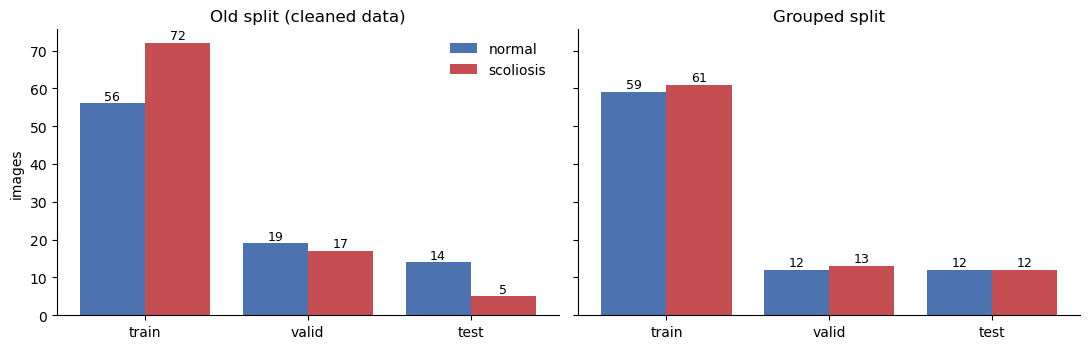

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, name, title in zip(axes, ['cleaned', 'grouped'], ['Old split (cleaned data)', 'Grouped split']):
    d = pd.read_csv(EVAL_DIR / 'split_quality_summary.csv'); d = d[d.dataset == name].set_index('split').loc[['train', 'valid', 'test']]
    x = np.arange(3)
    ax.bar(x - 0.2, d['normal'], 0.4, label='normal', color='#4C72B0'); ax.bar(x + 0.2, d['scoliosis'], 0.4, label='scoliosis', color='#C44E52')
    for i, (n, s) in enumerate(zip(d['normal'], d['scoliosis'])): ax.text(i - 0.2, n + 1, n, ha='center', fontsize=9); ax.text(i + 0.2, s + 1, s, ha='center', fontsize=9)
    ax.set_xticks(x, ['train', 'valid', 'test']); ax.set_title(title)
axes[0].set_ylabel('images'); axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

## 2. Models

Settings are read from each run's `args.yaml`. The validation curve is on the grouped **valid** split (25 images).

,grouped conservative
data,scoliosis_grouped_split.yaml
epochs,100
patience,20
imgsz,640
batch,8
seed,0
fliplr,0.0
mosaic,0.0
degrees,5.0
translate,0.05


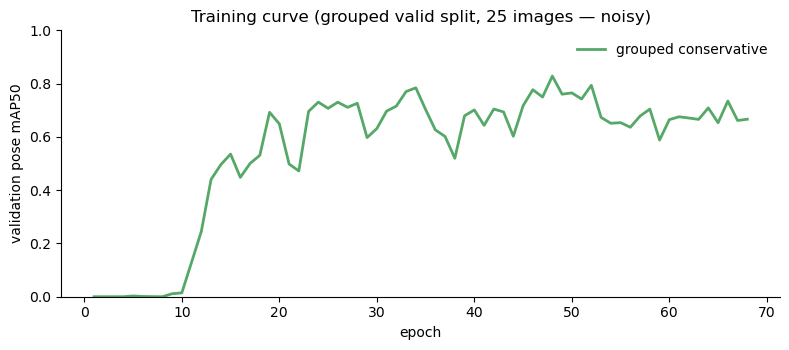

In [4]:
KEYS = ['data', 'epochs', 'patience', 'imgsz', 'batch', 'seed', 'fliplr', 'mosaic', 'degrees', 'translate', 'scale', 'hsv_v', 'erasing']
run_dirs, setup = {}, {}
for label, meta in metas.items():
    run_dir = (ROOT / meta['weights']).parents[1]          # <project>/<run>/weights/best.pt -> <project>/<run>
    run_dirs[label] = run_dir
    args = yaml.safe_load((run_dir / 'args.yaml').read_text(encoding='utf-8'))
    row = {k: args.get(k) for k in KEYS}; row['data'] = Path(str(row['data'])).name
    res = pd.read_csv(run_dir / 'results.csv'); res.columns = [c.strip() for c in res.columns]
    row['epochs actually run'] = len(res)
    row['best valid pose mAP50'] = round(res['metrics/mAP50(P)'].max(), 3)
    row['final valid pose mAP50'] = round(res['metrics/mAP50(P)'].iloc[-1], 3)
    setup[label] = row
display(pd.DataFrame(setup))

fig, ax = plt.subplots(figsize=(8, 3.6))
for label, run_dir in run_dirs.items():
    r = pd.read_csv(run_dir / 'results.csv'); r.columns = [c.strip() for c in r.columns]
    ax.plot(r['epoch'], r['metrics/mAP50(P)'], color=COLORS[label], lw=2, label=label)
ax.set_xlabel('epoch'); ax.set_ylabel('validation pose mAP50'); ax.set_ylim(0, 1); ax.legend(frameon=False)
ax.set_title('Training curve (grouped valid split, 25 images — noisy)')
plt.tight_layout(); plt.show()

## 3. Test results (grouped test split, 24 images: 12 normal, 12 scoliosis)

Measurement plausibility (confidence, geometry, reliability) is shown first, then classification. Note that the reliability numbers measure whether keypoints are *plausible*, not whether they are *correct* — accuracy against the ground truth is in section 4.

In [5]:
def summarise(df):
    flags = df['anatomy_warning_flags'].fillna('')
    has_geom = df.valid_spine_geometry == True
    pred = df.dropna(subset=['predicted_class'])
    sc, nm = df[df.ground_truth_class == 'scoliosis'], df[df.ground_truth_class == 'normal']
    return {
        'Test images':                                  len(df),
        'Images with a prediction':                     len(pred),
        'Mean keypoint confidence':                     round(df.mean_confidence.mean(), 3),
        'Valid spine geometry (%)':                     round(100 * has_geom.mean(), 1),
        'Mean anatomy reliability score':               round(df.anatomy_reliability_score.mean(), 3),
        'Reliability = high (images)':                  int((df.reliability_level == 'high').sum()),
        'Shoulder warnings, of images with geometry (%)': round(100 * flags[has_geom].str.contains('shoulder').mean(), 1),
        'Retake/review recommended (%)':                round(100 * df.retake_or_review_recommended.mean(), 1),
        'Classification accuracy (predicted only)':    round(pred.classification_correct.mean(), 3),
        'Accuracy, missed detections count as wrong':   round(pred.classification_correct.sum() / len(df), 3),
        'Scoliosis recall (of all scoliosis images)':   round((sc.predicted_class == 'scoliosis').sum() / len(sc), 3),
        'Normal specificity (of all normal images)':    round((nm.predicted_class == 'normal').sum() / len(nm), 3),
    }

metrics = pd.DataFrame({label: summarise(df) for label, df in results.items()})
display(metrics)

,grouped conservative
Test images,24.000
Images with a prediction,23.000
Mean keypoint confidence,0.935
Valid spine geometry (%),95.800
Mean anatomy reliability score,0.955
Reliability = high (images),23.000
"Shoulder warnings, of images with geometry (%)",0.000
Retake/review recommended (%),4.200
Classification accuracy (predicted only),0.609
"Accuracy, missed detections count as wrong",0.583


predicted,normal,scoliosis,no detection
true class,,,
normal,9,2,1
scoliosis,7,5,0


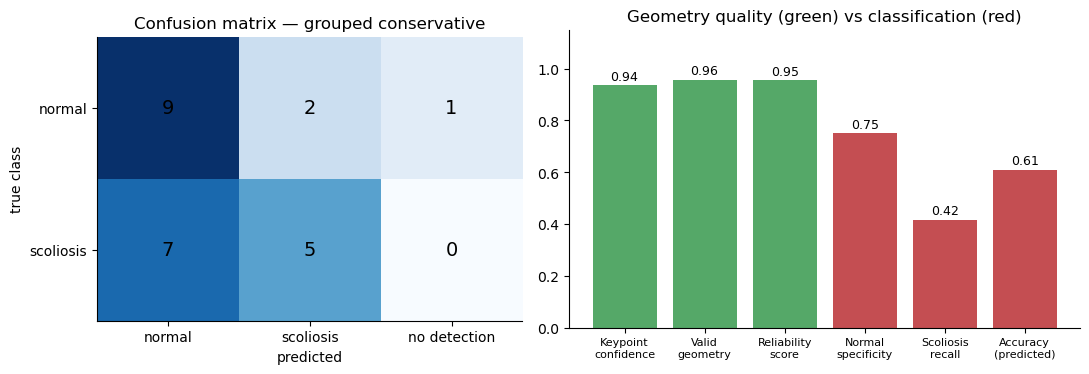

In [6]:
label = list(results)[0]
df = results[label]
conf = pd.crosstab(df.ground_truth_class, df.predicted_class.fillna('no detection')).reindex(index=['normal', 'scoliosis'])
conf = conf.reindex(columns=[c for c in ['normal', 'scoliosis', 'no detection'] if c in conf.columns], fill_value=0)
display(conf.rename_axis(index='true class', columns='predicted'))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={'width_ratios': [1, 1.2]})
im = axes[0].imshow(conf.values, cmap='Blues')
axes[0].set_xticks(range(conf.shape[1]), conf.columns); axes[0].set_yticks(range(conf.shape[0]), conf.index)
for i in range(conf.shape[0]):
    for j in range(conf.shape[1]): axes[0].text(j, i, conf.values[i, j], ha='center', va='center', fontsize=14, color='black')
axes[0].set_xlabel('predicted'); axes[0].set_ylabel('true class'); axes[0].set_title(f'Confusion matrix — {label}')

q = metrics[label]
names = ['Keypoint\nconfidence', 'Valid\ngeometry', 'Reliability\nscore', 'Normal\nspecificity', 'Scoliosis\nrecall', 'Accuracy\n(predicted)']
vals = [q['Mean keypoint confidence'], q['Valid spine geometry (%)'] / 100, q['Mean anatomy reliability score'],
        q['Normal specificity (of all normal images)'], q['Scoliosis recall (of all scoliosis images)'], q['Classification accuracy (predicted only)']]
cols = ['#55A868'] * 3 + ['#C44E52'] * 3
bars = axes[1].bar(range(6), vals, color=cols)
for b, v in zip(bars, vals): axes[1].text(b.get_x() + b.get_width() / 2, v + 0.02, f'{v:.2f}', ha='center', fontsize=9)
axes[1].set_xticks(range(6), names, fontsize=8); axes[1].set_ylim(0, 1.15)
axes[1].set_title('Geometry quality (green) vs classification (red)')
plt.tight_layout(); plt.show()

## 4. Where the errors are

The grouped test images come from **14 photo groups**, so one photo can contribute several test images. Errors from the same photo are not independent evidence.

In [7]:
m = manifest.set_index('image')
d = df.copy()
d['photo_group'] = d.capture_id.map(m.photo_group)
d['outcome'] = np.where(d.predicted_class.isna(), 'no detection', np.where(d.classification_correct == 1, 'correct', 'wrong'))
grp = d.groupby('photo_group').agg(
    images=('capture_id', 'count'), true_class=('ground_truth_class', 'first'),
    correct=('outcome', lambda s: int((s == 'correct').sum())), wrong=('outcome', lambda s: int((s == 'wrong').sum())),
    no_detection=('outcome', lambda s: int((s == 'no detection').sum())))
display(grp[(grp.wrong > 0) | (grp.no_detection > 0)].sort_values('wrong', ascending=False))
bad = grp[grp.wrong > 0]
print(f'{int(grp.wrong.sum())} wrong predictions come from {len(bad)} of {len(grp)} photo groups; '
      f'{int(bad[bad.true_class == "scoliosis"].wrong.sum())} of them are scoliosis images predicted as normal '
      f'({len(bad[bad.true_class == "scoliosis"])} photo groups).')

,images,true_class,correct,wrong,no_detection
photo_group,,,,,
51,3,scoliosis,0,3,0
22,2,scoliosis,0,2,0
61,3,scoliosis,1,2,0
30,4,normal,3,1,0
104,1,normal,0,1,0
90,1,normal,0,0,1


9 wrong predictions come from 5 of 14 photo groups; 7 of them are scoliosis images predicted as normal (3 photo groups).


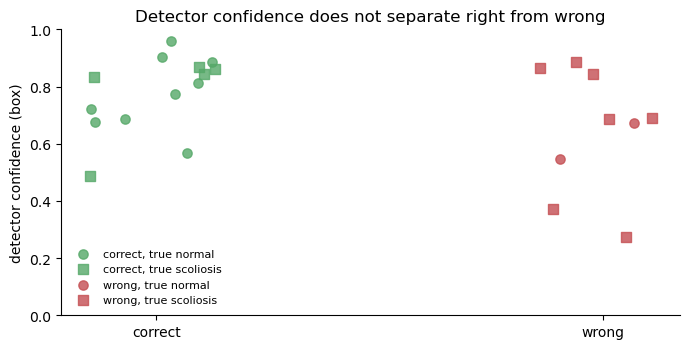

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.6))
rng = np.random.default_rng(0)
for k, (outcome, colr) in enumerate([('correct', '#55A868'), ('wrong', '#C44E52')]):
    for cls, mk in (('normal', 'o'), ('scoliosis', 's')):
        sel = d[(d.outcome == outcome) & (d.ground_truth_class == cls)]
        ax.scatter(np.full(len(sel), k) + rng.uniform(-0.15, 0.15, len(sel)), sel.detection_confidence, c=colr, marker=mk, s=45, alpha=0.8,
                   label=f'{outcome}, true {cls}')
ax.set_xticks([0, 1], ['correct', 'wrong']); ax.set_ylabel('detector confidence (box)'); ax.set_ylim(0, 1)
ax.set_title('Detector confidence does not separate right from wrong'); ax.legend(frameon=False, fontsize=8, loc='lower left')
plt.tight_layout(); plt.show()

### Plausible is not the same as accurate

The reliability score and the "curvature features reliable" flag check whether the keypoints are **plausible** (ordered, evenly spaced, shoulders on opposite sides). They do not check that the keypoints are **correct**. Here the predicted keypoints are compared with the **ground-truth keypoints**, with errors expressed as a fraction of each image's spine length.

In [9]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
import cv2
from ultralytics import YOLO
from src.FeatureExtraction.spine_geometry import extract_spine_geometry

test_dir = SPLIT_DIR / 'test'

model = YOLO(str(ROOT / metas[label]['weights']))
rows = []
for stem, cls in zip(d.capture_id, d.ground_truth_class):
    img_path = next((test_dir / 'images').glob(f'{stem}.*'))
    img = cv2.imdecode(np.fromfile(str(img_path), np.uint8), cv2.IMREAD_COLOR)
    res = model(img, verbose=False)[0]
    if res.boxes is None or len(res.boxes) == 0:
        continue
    best = int(res.boxes.conf.cpu().numpy().argmax())
    pred = res.keypoints.xyn[best].cpu().numpy()                                   # normalised x, y
    t = (test_dir / 'labels' / f'{stem}.txt').read_text().split()
    gt = np.array(t[5:41], float).reshape(12, 3)[:, :2]
    spine_len = np.linalg.norm(gt[8] - gt[0])
    err = np.linalg.norm(pred - gt, axis=1) / spine_len
    gt_px = np.c_[gt * 640, np.ones(12)]
    g = extract_spine_geometry(gt_px)                                              # same geometry code, on the TRUE keypoints
    rows.append({'stem': stem, 'class': cls, 'spine points': err[:9].mean(), 'intermediate spine': err[1:8].mean(),
                 'sideways error, intermediate spine': np.abs(pred[1:8, 0] - gt[1:8, 0]).mean() / spine_len,
                 'shoulders': err[[9, 10]].mean(), 'head/neck': err[11],
                 'true wander': g['normalized_max_lateral_deviation'], 'predicted wander': float(d.set_index('capture_id').loc[stem, 'normalized_max_lateral_deviation'])})
acc = pd.DataFrame(rows)
print('Keypoint error as a fraction of spine length (lower is better):')
display(acc[['spine points', 'intermediate spine', 'sideways error, intermediate spine', 'shoulders', 'head/neck']].mean().round(3).to_frame('mean error'))
print('By true class:')
display(acc.groupby('class')[['spine points', 'sideways error, intermediate spine', 'shoulders']].mean().round(3))

Keypoint error as a fraction of spine length (lower is better):


,mean error
spine points,0.054
intermediate spine,0.054
"sideways error, intermediate spine",0.031
shoulders,0.116
head/neck,0.057


By true class:


,spine points,"sideways error, intermediate spine",shoulders
class,,,
normal,0.047,0.025,0.074
scoliosis,0.060,0.036,0.155


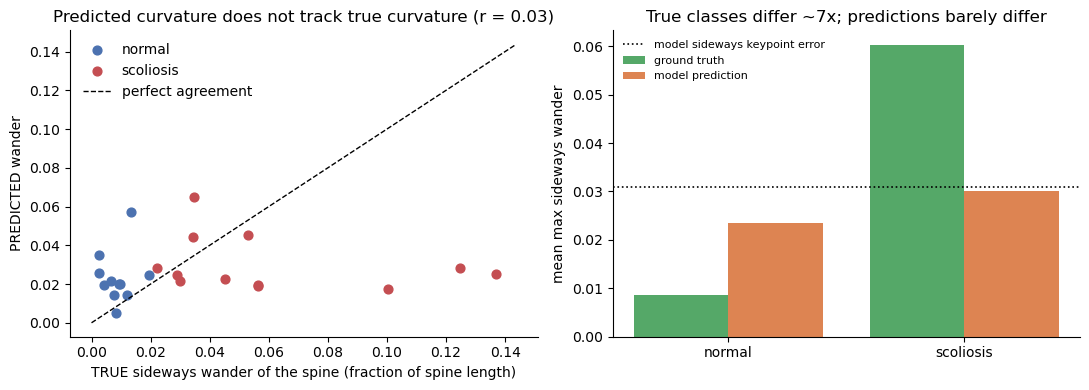

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
cls_col = {'normal': '#4C72B0', 'scoliosis': '#C44E52'}
for c, grp_ in acc.groupby('class'):
    axes[0].scatter(grp_['true wander'], grp_['predicted wander'], c=cls_col[c], label=c, s=40)
lim = max(acc['true wander'].max(), acc['predicted wander'].max()) * 1.05
axes[0].plot([0, lim], [0, lim], 'k--', lw=1, label='perfect agreement')
r = np.corrcoef(acc['true wander'], acc['predicted wander'])[0, 1]
axes[0].set_xlabel('TRUE sideways wander of the spine (fraction of spine length)'); axes[0].set_ylabel('PREDICTED wander')
axes[0].set_title(f'Predicted curvature does not track true curvature (r = {r:.2f})'); axes[0].legend(frameon=False)

means = acc.groupby('class')[['true wander', 'predicted wander']].mean().loc[['normal', 'scoliosis']]
x = np.arange(2)
axes[1].bar(x - 0.2, means['true wander'], 0.4, label='ground truth', color='#55A868')
axes[1].bar(x + 0.2, means['predicted wander'], 0.4, label='model prediction', color='#DD8452')
axes[1].axhline(acc['sideways error, intermediate spine'].mean(), color='k', ls=':', lw=1.2, label='model sideways keypoint error')
axes[1].set_xticks(x, ['normal', 'scoliosis']); axes[1].set_ylabel('mean max sideways wander'); axes[1].legend(frameon=False, fontsize=8)
axes[1].set_title('True classes differ ~7x; predictions barely differ')
plt.tight_layout(); plt.show()

## 5. Visual examples

Left: the model's prediction with the geometry layer's verdict. Right: ground-truth keypoints from the dataset label (same image). In the missed scoliosis cases the predicted spine is close to a straight vertical line, while the ground-truth spine wanders — the model finds the spine but not its curve.

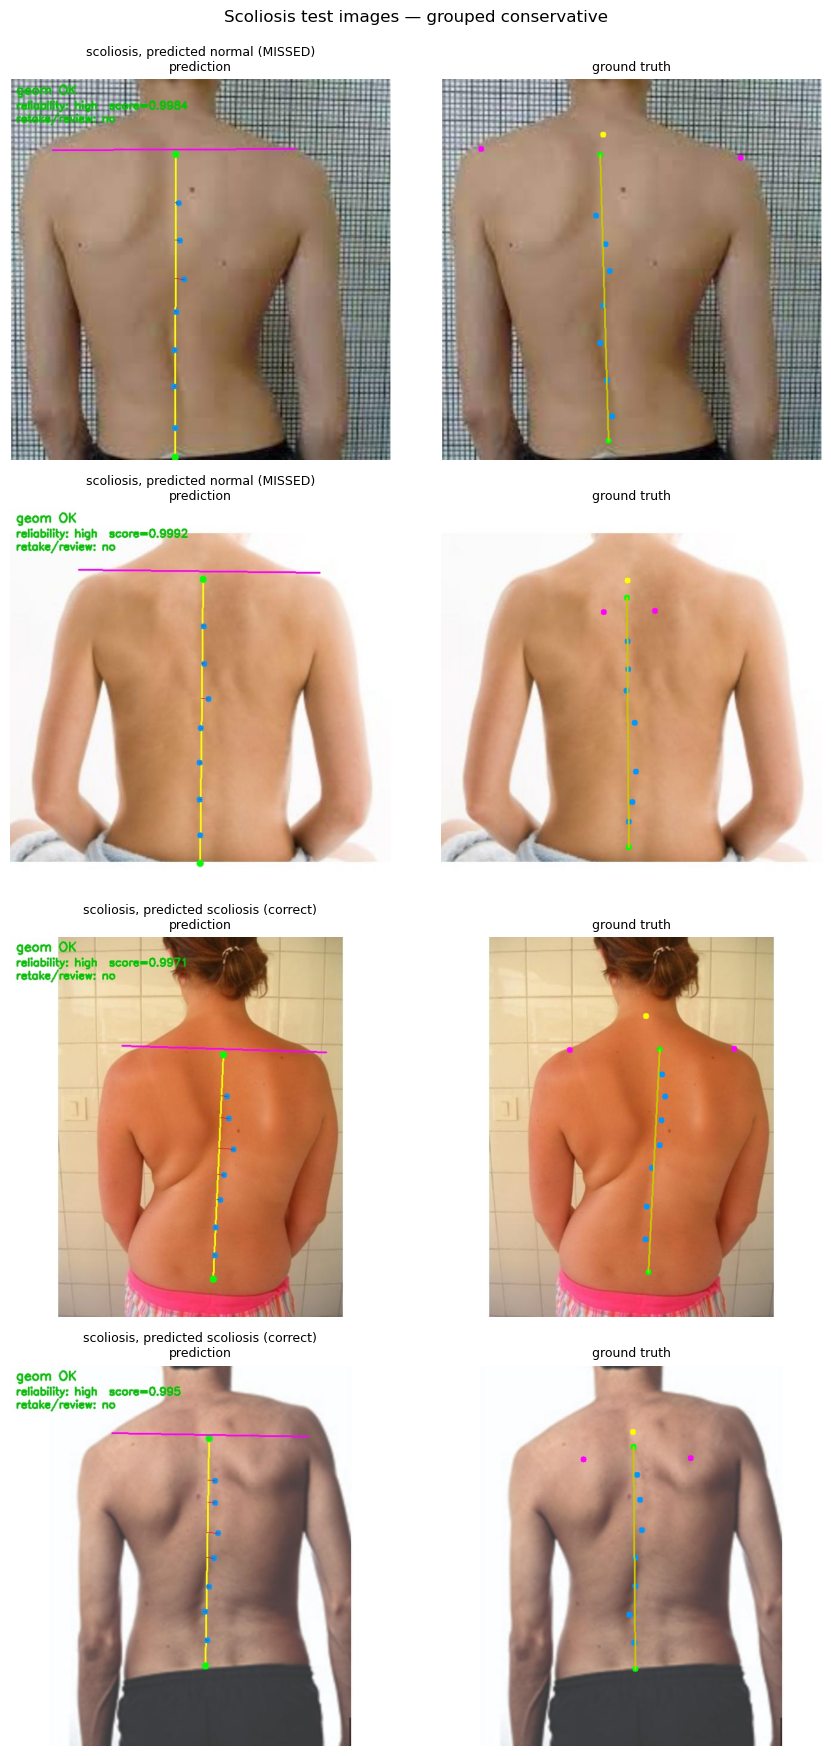

In [11]:
import cv2
from src.Evaluation.dataset_eda import draw_overlay, parse_label_file, imdecode_unicode

meta = metas[label]
out_dir = ROOT / 'Data' / 'Processed' / 'geometry_debug' / f"grouped_{meta['tag']}"
test_dir = SPLIT_DIR / 'test'

d1 = d.drop_duplicates('photo_group')            # one image per photo group, so the examples are different photos
missed = d1[(d1.ground_truth_class == 'scoliosis') & (d1.outcome == 'wrong')].sort_values('detection_confidence', ascending=False).head(2)
hit    = d1[(d1.ground_truth_class == 'scoliosis') & (d1.outcome == 'correct')].sort_values('detection_confidence', ascending=False).head(2)
picks = [(r.capture_id, f'scoliosis, predicted {r.predicted_class} (MISSED)') for r in missed.itertuples()] + \
        [(r.capture_id, f'scoliosis, predicted {r.predicted_class} (correct)') for r in hit.itertuples()]

todo = [s for s, _ in picks if not (out_dir / f'{s}_geometry.jpg').exists()]
if todo:
    subprocess.run([sys.executable, str(ROOT / 'src/Evaluation/debug_spine_geometry.py'), '--weights', str(ROOT / meta['weights']),
                    '--data-yaml', str(ROOT / meta['eval_data_yaml']), '--split', 'test', '--out-dir', str(out_dir), '--stems', *todo],
                   cwd=ROOT, capture_output=True)

def gt_overlay(stem):
    img = imdecode_unicode(next((test_dir / 'images').glob(f'{stem}.*')))
    objects = parse_label_file(test_dir / 'labels' / f'{stem}.txt', {0, 1})['objects']
    return cv2.cvtColor(draw_overlay(img, objects), cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(len(picks), 2, figsize=(9, 4.4 * len(picks)), squeeze=False)
for r, (stem, tag) in enumerate(picks):
    p = out_dir / f'{stem}_geometry.jpg'
    if p.exists(): axes[r, 0].imshow(mpimg.imread(p))
    axes[r, 0].set_title(f'{tag}\nprediction', fontsize=9); axes[r, 1].imshow(gt_overlay(stem)); axes[r, 1].set_title('ground truth', fontsize=9)
for ax in axes.ravel(): ax.axis('off')
plt.suptitle(f'Scoliosis test images — {label}', y=0.995); plt.tight_layout(); plt.show()

## 6. Compared with the old split (context only)

The same training recipe (cleaned data, conservative augmentation) was evaluated earlier on the **old** public test split. The two rows below use **different training sets and different test sets**, so this is **not a like-for-like comparison** — it only illustrates how much the old split's leakage flattered classification.

In [12]:
old_path = COMP_DIR / 'yolo_finetuned_scoliosis_test_cleaned_aug_trained.csv'
rows = {}
if old_path.exists():
    o = pd.read_csv(old_path); p = o.dropna(subset=['predicted_class']); sc = o[o.ground_truth_class == 'scoliosis']
    rows['OLD split — cleaned + conservative (historical, leaked)'] = {
        'test images': len(o), 'scoliosis in test': len(sc), 'accuracy (predicted)': round(p.classification_correct.mean(), 3),
        'scoliosis recall': f"{int((sc.predicted_class == 'scoliosis').sum())}/{len(sc)}",
        'shoulder warnings (%)': round(100 * o.anatomy_warning_flags.fillna('').str.contains('shoulder').mean(), 1),
        'mean reliability': round(o.anatomy_reliability_score.mean(), 3)}
g = results[label]; gp = g.dropna(subset=['predicted_class']); gs = g[g.ground_truth_class == 'scoliosis']
rows[f'GROUPED split — {label}'] = {
    'test images': len(g), 'scoliosis in test': len(gs), 'accuracy (predicted)': round(gp.classification_correct.mean(), 3),
    'scoliosis recall': f"{int((gs.predicted_class == 'scoliosis').sum())}/{len(gs)}",
    'shoulder warnings (%)': round(100 * g.anatomy_warning_flags.fillna('').str.contains('shoulder').mean(), 1),
    'mean reliability': round(g.anatomy_reliability_score.mean(), 3)}
display(pd.DataFrame(rows).T)

,test images,scoliosis in test,accuracy (predicted),scoliosis recall,shoulder warnings (%),mean reliability
"OLD split — cleaned + conservative (historical, leaked)",19,5,0.842,5/5,0.0,0.995
GROUPED split — grouped conservative,24,12,0.609,5/12,0.0,0.955


## 7. Baseline workflows: MediaPipe and pretrained YOLO

The two training-free baselines were re-run on the **same grouped test images** (24 images) so they can be compared with the fine-tuned model. Neither was trained on this data, so they were never exposed to these photos. `compare_workflows.py` also writes this table to `comparison_grouped_baselines.csv`.

**These are detection-quality numbers only.** The baselines predict no normal/scoliosis class and no spine geometry, so classification cannot be compared. "Valid measurement" is also defined differently for each workflow (MediaPipe: shoulder and hip landmarks visible; pretrained YOLO: the COCO shoulder and hip keypoints confident; fine-tuned: all 9 spine keypoints confident), so treat it as "did this workflow produce a usable measurement of *its own kind*", not as a like-for-like accuracy.

In [13]:
BASE = {
    'MediaPipe':         (COMP_DIR / f'mediapipe_{GROUPED}_test.csv', '#4C72B0'),
    'YOLO (pretrained)': (COMP_DIR / f'yolo_pretrained_{GROUPED}_test.csv', '#DD8452'),
}
base_frames = {}
for name, (path, _) in BASE.items():
    meta = read_meta(path)
    if path.exists() and meta and meta.get('eval_dataset') == GROUPED and meta.get('eval_split') == 'test':
        base_frames[name] = pd.read_csv(path)
    else:
        print(f'Missing or not on the grouped test split: {path.name}')
base_frames[f'YOLO fine-tuned ({label})'] = results[label]

def base_row(df):
    return {
        'Test images': len(df),
        'Pose found (%)': round(100 * df.pose_present.mean(), 1),
        'Valid measurement (%)': round(100 * df.valid_measurement.mean(), 1),
        'Normal images with a valid measurement': f"{int(df[df.ground_truth_class == 'normal'].valid_measurement.sum())}/12",
        'Scoliosis images with a valid measurement': f"{int(df[df.ground_truth_class == 'scoliosis'].valid_measurement.sum())}/12",
        'Mean keypoint confidence': round(df.mean_confidence.mean(), 3),
        'Mean missing keypoints': round(df.missing_keypoint_count.mean(), 2),
        'Mean time per image (ms, CPU)': round(1000 * df.processing_time_s.mean(), 1),
        'Predicts normal/scoliosis': 'yes' if 'predicted_class' in df.columns else 'no',
    }
display(pd.DataFrame({n: base_row(df) for n, df in base_frames.items()}))

,MediaPipe,YOLO (pretrained),YOLO fine-tuned (grouped conservative)
Test images,24,24,24
Pose found (%),87.5,100.0,95.8
Valid measurement (%),87.5,12.5,95.8
Normal images with a valid measurement,9/12,0/12,11/12
Scoliosis images with a valid measurement,12/12,3/12,12/12
Mean keypoint confidence,0.798,0.54,0.935
Mean missing keypoints,0.5,1.92,0.38
"Mean time per image (ms, CPU)",43.2,89.7,65.3
Predicts normal/scoliosis,no,no,yes


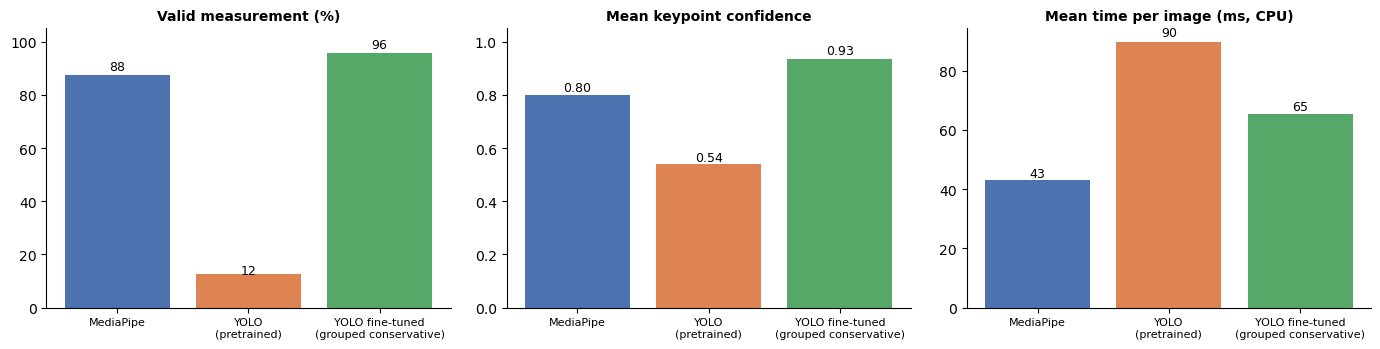

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
names = list(base_frames)
cols = ['#4C72B0', '#DD8452', '#55A868']
short = [n.replace(' (', '\n(') for n in names]
for ax, (title, fn, top) in zip(axes, [
        ('Valid measurement (%)', lambda d: 100 * d.valid_measurement.mean(), 105),
        ('Mean keypoint confidence', lambda d: d.mean_confidence.mean(), 1.05),
        ('Mean time per image (ms, CPU)', lambda d: 1000 * d.processing_time_s.mean(), None)]):
    vals = [fn(base_frames[n]) for n in names]
    bars = ax.bar(range(len(vals)), vals, color=cols[:len(vals)])
    for b, v in zip(bars, vals): ax.text(b.get_x() + b.get_width() / 2, v * 1.02 + (0 if top else 0), f'{v:.2f}' if v < 5 else f'{v:.0f}', ha='center', fontsize=9)
    ax.set_xticks(range(len(vals)), short, fontsize=8); ax.set_title(title, fontsize=10, fontweight='bold')
    if top: ax.set_ylim(0, top)
plt.tight_layout(); plt.show()

## 8. Interpretation

**The model finds the spine, but plausible is not accurate.** Mean keypoint confidence is 0.94, 23 of 24 images reach `high` reliability, and there are no shoulder warnings (the one `invalid` image is the single missed detection). But against the **ground truth** (section 4): spine keypoints are off by about 5% of spine length, the sideways error of the intermediate spine points is about 3%, and the **shoulders are off by about 12%** (about 16% on scoliosis images). The shoulder *warnings* are gone because the points now sit plausibly, not because they are accurate. The earlier shoulder improvement therefore holds on photos the model never saw a copy of, but only in the sense of plausibility. (The likely cause — default horizontal flipping with an identity flip map — is still unproven; it is one training recipe.)

**The curvature signal is not recovered.** In the ground truth, scoliosis spines wander sideways about **7 times more** than normal ones (0.060 vs 0.0085 of spine length). In the model's predictions the difference is only about 1.3 times (0.030 vs 0.023), and predicted wander is essentially uncorrelated with the true wander (r about 0.03). The model's sideways error is as large as the real signal, so the curve-based features (`curve_smoothness_score`, lateral deviation) cannot separate the classes. The reliability score and the "curvature features reliable" flag stay near 1.0 anyway, because they test plausibility, not correctness.

**Classification does not hold up.** Accuracy is 0.61 (14 of 23 predicted images; 0.58 counting the missed detection). Scoliosis recall is **5 of 12**: 7 of the 12 scoliosis images were predicted as normal, and 2 of the 12 normal images as scoliosis. The 7 missed scoliosis images come from only **3 photos** (several copies of each), so the real evidence is thinner than "7 errors" suggests. For a screening-support tool, missed scoliosis is the costly error. Detector confidence does not warn about the errors: wrong predictions span about 0.3–0.9, overlapping the correct ones (section 4).

**The old split flattered classification.** The same recipe scored 0.84 accuracy and 5/5 scoliosis recall on the old test split; on the grouped test it is 0.61 and 5/12 (section 6; different test sets, so indicative only). That gap is what leakage looks like: with copies of the test photos in training, classification looked solved when it was partly memorised.

**Against the baselines, fine-tuning clearly helps detection.** On the grouped test images the pretrained YOLO produces a usable measurement on only 3 of 24 images (it finds a person in every image but its COCO shoulder/hip keypoints are not confident on bare backs), MediaPipe on 21 of 24 (3 normal images with no pose found), and the fine-tuned model on 23 of 24. Only the fine-tuned model gives spine keypoints, geometry and a class. But "valid" means different things for each workflow, MediaPipe is the fastest (about 43 ms vs 65 ms on CPU), and the fine-tuned model's classification (section 3) is weak, so the advantage is in measurement coverage, not in screening accuracy.

**The accuracy target is not met and is not claimed.** The ideal target is around 95%; this model is far from it on a fair test.

## 9. Limitations and next steps

**Limitations**
- **Small test set** — 24 images from 14 photo groups; one image is about 4 points of accuracy, and errors cluster within photos.
- **One grouped model, one training run** — no grouped default-augmentation baseline, no repeated seeds, no k-fold. We cannot say whether conservative augmentation helped or hurt classification or keypoint accuracy.
- **Unstable training signal** — validation pose mAP50 peaked at 0.83 but ended at 0.67 (early-stopped at epoch 68 on a 25-image validation set); the saved `best.pt` is the best-fitness epoch.
- **Reliability is plausibility, not accuracy** — a high reliability score does not mean the keypoints or curvature are correct (section 4).
- **Class comes from the detector box** — the normal/scoliosis label is the YOLO box class, not a dedicated classifier, and the labels are public and non-clinical (4 mixed-label photo groups were excluded; others may still be wrong).
- **Non-diagnostic** — screening-support indicators only; no Cobb angle or angle of trunk rotation.

**Next steps**
1. Train a **grouped default-augmentation baseline** (same seed) and compare it with the conservative model on this test set (`compare_original_vs_cleaned.py`), judging **keypoint accuracy against ground truth**, not only reliability.
2. Look at the 3 photos behind the missed scoliosis cases (photo groups 51, 22 and 61 in `split_manifest.csv`) for label problems or unusual images.
3. Treat sideways keypoint error as the key quantity to reduce: it is about as large as the curvature signal. More or better-labelled data is the most direct lever.
4. Run **3-fold validation on the grouped data** (`create_kfold_splits.py`) for the best configuration to see how stable results are across splits.
5. Decide whether classification should rely on the detector box class at all, or be assessed separately.